# Recomendadores clásicos vs. generativos (paper GR-LLMs)

**Paper:** Yang, Lin, Xue y Zhang (AMAP, Alibaba), *GR-LLMs: Recent Advances in Generative Recommendation Based on Large Language Models*, arXiv 2507.06507 (2025).

El paper es un **survey**: no propone un modelo propio ni trae código o experimentos. Cuenta cómo la recomendación pasó del filtrado colaborativo y la factorización de matrices, a las redes profundas, y de ahí a los modelos **generativos**, que tratan el historial del usuario como una **secuencia** y predicen el próximo ítem con transformers o LLMs.

Acá implementamos, en versión chica y para MovieLens small, las ideas del paper que se pueden correr sin infraestructura industrial, y las comparamos con lo que vimos en clase (contenido, colaborativo user-user e híbrido).

| Método | De dónde sale | Qué hacemos acá | Diferencia con el original |
|---|---|---|---|
| Popularidad | referencia | las películas más calificadas | no es del paper |
| Contenido, Colaborativo, Híbrido | clase y sección 1 del paper | los mismos algoritmos de `recomendadores_peliculas`, vectorizados | ninguna (se verifica contra el código de la clase) |
| SASRec | Kang y McAuley 2018, citado en la introducción | transformer causal que predice el próximo ítem, entropía cruzada sobre todo el catálogo | versión chica |
| HSTU-lite | Zhai et al. 2024 (secciones 3 y 4.2) | atención puntual con SiLU en lugar de softmax, con gating | simplificado: sin sesgos de tiempo/posición relativos ni M-FALCON |
| KuaiFormer-style | KuaiFormer (Tabla 1: contrastivo in-batch) | mismo transformer, entrenado con InfoNCE con negativos del batch | sin compresión adaptativa ni múltiples queries |

**No implementamos** (requieren datos, infraestructura o LLMs que no tenemos): OneRec, MTGR, URM, EGA-V1/V2 y OneSug (sistemas industriales de punta a punta), S-DPO y RosePO (alineación por preferencias), los métodos con prompts a LLMs (LLMTreeRec, LLM-Rec), los multimodales (Tabla 2), y HLLM, LEARN y LUM (dependen de modelos de CTR con muchas features).

## Cómo vamos a comparar

Usamos el **timestamp** de cada calificación. Para cada usuario ordenamos sus películas por fecha y escondemos las últimas `N_ROLL`:

- **Entrenamiento:** todo lo anterior. Ningún modelo ve las películas escondidas.
- **Evaluación iterativa (próxima película):** en cada paso el modelo ve el historial hasta ese momento y recomienda 10 películas. Es un **acierto** si la próxima película que el usuario realmente vio está en la lista. Después se revela esa película y se repite, `N_ROLL` veces por usuario.
- **Evaluación de ventana futura:** con el historial de entrenamiento, el modelo recomienda 10 y contamos cuántas de las `N_ROLL` películas siguientes aparecen.
- **Validación (modelos neuronales):** el último item de entrenamiento de cada usuario se usa para validar y cortar el entrenamiento a tiempo (early stopping). Las películas escondidas nunca se usan para elegir nada.
- **Matriz de confusión:** TP = recomendada y vista después; FP = recomendada y no vista; FN = vista después y no recomendada; TN = el resto del catálogo. Las películas ya vistas nunca se recomiendan.

Métricas: HR@10 (acierto), NDCG@10 y MRR@10 (qué tan arriba está el acierto), precisión@10 y cobertura (cuántas películas distintas se recomiendan en total).

Limitaciones del protocolo, que valen igual para todos los métodos:
- Muchos ratings de MovieLens tienen el mismo timestamp (se calificaron todos juntos). Su orden se desempata al azar, así que parte del "orden" es arbitrario.
- Los vecinos del colaborativo y el entrenamiento de los modelos usan datos de otros usuarios que pueden ser posteriores al momento a predecir. Es una limitación habitual con MovieLens.
- "Ver" una película significa haberla calificado.

In [1]:
import math, time, warnings
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.feature_extraction.text import TfidfVectorizer
from pathlib import Path

warnings.filterwarnings("ignore")

# ---- Configuración del proyecto ---------------------------------------------

# Carpeta que contiene ratings.csv y movies.csv.
# Por defecto, se espera una carpeta "data" dentro del proyecto.
# Cada usuario puede cambiar esta ruta según dónde guarde los archivos.
DATA_DIR = Path("data")

N_USERS = 1500
SEED = 0
K = 10
N_ROLL = 5
MAX_LEN = 30

# Métodos clásicos
K_NEIGHBORS, MIN_COMMON, MIN_NEIGHBORS, ALPHA = 15, 10, 3, 0.5

# Modelos neuronales
D_MODEL, LAYERS, HEADS, DROPOUT = 64, 2, 2, 0.2
EPOCHS, BATCH, LR = 150, 128, 1e-3
PATIENCE = 10
MIN_EPOCHS = 30
SEEDS_EXTRA = [1, 2]

device = "cuda" if torch.cuda.is_available() else "cpu"

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Dispositivo:", device)
print("Carpeta de datos:", DATA_DIR.resolve())

Dispositivo: cuda (si dice cpu: Entorno de ejecución > Cambiar tipo de entorno > GPU T4)


## 1. Datos y partición temporal

In [ ]:
from pathlib import Path
import urllib.request, zipfile, shutil

DATA_DIR = Path("data")
if not (DATA_DIR / "ratings.csv").exists():
    DATA_DIR.mkdir(exist_ok=True)
    urllib.request.urlretrieve("https://files.grouplens.org/datasets/movielens/ml-20m.zip", "ml.zip")
    with zipfile.ZipFile("ml.zip") as z:
        for nombre in ("ratings.csv", "movies.csv"):
            with z.open(f"ml-20m/{nombre}") as src, open(DATA_DIR / nombre, "wb") as dst:
                shutil.copyfileobj(src, dst)
    Path("ml.zip").unlink()
print("Datos listos en", DATA_DIR.resolve())

In [3]:
# ---- Carga y validación de datos --------------------------------------------

ratings_path = DATA_DIR / "ratings.csv"
movies_path = DATA_DIR / "movies.csv"

missing_files = [
    str(path)
    for path in (ratings_path, movies_path)
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "No se encontraron los siguientes archivos:\n"
        + "\n".join(missing_files)
        + "\n\nDescargá MovieLens y colocá ambos CSV en la carpeta "
          "indicada por DATA_DIR, o modificá DATA_DIR en la configuración."
    )

ratings = pd.read_csv(
    ratings_path,
    dtype={
        "userId": "int32",
        "movieId": "int32",
        "rating": "float32",
    },
)

movies = pd.read_csv(movies_path)

required_ratings = {"userId", "movieId", "rating", "timestamp"}
required_movies = {"movieId", "title", "genres"}

if not required_ratings.issubset(ratings.columns):
    raise ValueError(
        f"ratings.csv debe contener las columnas: "
        f"{sorted(required_ratings)}"
    )

if not required_movies.issubset(movies.columns):
    raise ValueError(
        f"movies.csv debe contener las columnas: "
        f"{sorted(required_movies)}"
    )

print("Datos cargados correctamente.")
print(f"Ratings: {len(ratings):,} filas")
print(f"Películas: {len(movies):,} filas")

# Muestra de usuarios: la matriz usuario-película es densa y con 20M de ratings no entra en memoria.
# Con ml-latest-small (610 usuarios) no cambia nada.
cnt = ratings["userId"].value_counts()
elegibles = cnt[(cnt >= N_ROLL + 5) & (cnt <= 1000)].index
if len(elegibles) > N_USERS:
    usuarios = np.random.default_rng(SEED).choice(elegibles, N_USERS, replace=False)
    ratings = ratings[ratings["userId"].isin(usuarios)]
    # El filtro de películas se calcula SIN las últimas N_ROLL de cada usuario (las escondidas), para no filtrar con información del futuro.
    ord_ = ratings.sample(frac=1, random_state=SEED).sort_values(["userId", "timestamp"], kind="stable")
    ic = ord_.loc[ord_.groupby("userId").cumcount(ascending=False) >= N_ROLL, "movieId"].value_counts()
    ratings = ratings[ratings["movieId"].isin(ic[ic >= 10].index)]
    movies = movies[movies["movieId"].isin(ratings["movieId"].unique())].reset_index(drop=True)
print(ratings["userId"].nunique(), "usuarios |", len(movies), "películas |", len(ratings), "ratings")

item_ids = movies["movieId"].to_numpy()
item_index = {m: i for i, m in enumerate(item_ids)}
n_items = len(item_ids)
ratings = ratings[ratings["movieId"].isin(item_index)]

# Orden temporal por usuario. Con timestamps repetidos se mezcla al azar antes de ordenar,
# para que el desempate no dependa del movieId.
r = ratings.sample(frac=1, random_state=SEED).sort_values(["userId", "timestamp"], kind="stable")
seq_items, seq_ratings, seq_ts = [], [], []
for _, g in r.groupby("userId", sort=True):
    if len(g) < N_ROLL + 5:
        continue
    seq_items.append(g["movieId"].map(item_index).to_numpy())
    seq_ratings.append(g["rating"].to_numpy(dtype=np.float64))
    seq_ts.append(g["timestamp"].to_numpy())

n_users = len(seq_items)
n_seq = np.array([len(s) for s in seq_items])
n_train = n_seq - N_ROLL

# Consultas de evaluación: (usuario, paso). En el paso j el historial incluye las j películas
# reveladas, y el objetivo es la siguiente.
q_user = np.repeat(np.arange(n_users), N_ROLL)
q_step = np.tile(np.arange(N_ROLL), n_users)
q_len = n_train[q_user] + q_step
q_target = np.array([seq_items[u][l] for u, l in zip(q_user, q_len)])
Q = len(q_user)

# Matriz usuario-película solo con la parte de entrenamiento
R_tr = np.zeros((n_users, n_items))
for u in range(n_users):
    R_tr[u, seq_items[u][:n_train[u]]] = seq_ratings[u][:n_train[u]]
M_tr = (R_tr != 0).astype(float)
mean_tr = R_tr.sum(1) / np.maximum(M_tr.sum(1), 1)
D_tr = (R_tr - mean_tr[:, None]) * M_tr          # ratings centrados por usuario (para el colaborativo)

def hist_matrix(qi):
    """Matriz (consultas x películas) con el historial de cada consulta."""
    H = np.zeros((len(qi), n_items))
    for row, q in enumerate(qi):
        u, l = q_user[q], q_len[q]
        H[row, seq_items[u][:l]] = seq_ratings[u][:l]
    return H

mismo_ts = np.mean([seq_ts[u][l] == seq_ts[u][l - 1] for u, l in zip(q_user, q_len)])
print(f"{n_users} usuarios | {n_items} películas | {n_seq.sum()} ratings | {Q} consultas de evaluación ({N_ROLL} por usuario)")
print(f"{mismo_ts:.0%} de las películas a predecir tienen el mismo timestamp que la anterior (su orden es arbitrario)")

1500 usuarios | 2896 películas | 172640 ratings
1500 usuarios | 2896 películas | 172640 ratings | 7500 consultas de evaluación (5 por usuario)
21% de las películas a predecir tienen el mismo timestamp que la anterior (su orden es arbitrario)


## 2. Evaluación

In [4]:
RESULTS, GROUP = {}, {}

def top_k_from_scores(S, seen, k):
    S = np.where(np.isnan(S) | seen, -np.inf, S)
    idx = np.argpartition(-S, k, axis=1)[:, :k]
    vals = np.take_along_axis(S, idx, 1)
    order = np.argsort(-vals, axis=1)
    idx, vals = np.take_along_axis(idx, order, 1), np.take_along_axis(vals, order, 1)
    idx[~np.isfinite(vals)] = -1              # menos de k candidatas: lista más corta
    return idx

def evaluate(recs):
    match = recs == q_target[:, None]
    hit, pos = match.any(1), match.argmax(1)
    n_recs = (recs >= 0).sum(1)
    out = dict(
        HR=hit.mean(), HR_ic=1.96 * hit.std() / np.sqrt(Q),
        NDCG=np.where(hit, 1 / np.log2(pos + 2), 0.0).mean(),
        MRR=np.where(hit, 1 / (pos + 1), 0.0).mean(),
        Prec=hit.sum() / max(n_recs.sum(), 1),
        Cob=len(np.unique(recs[recs >= 0])) / n_items, n_recs=n_recs.mean(),
    )
    # Matriz de confusión, evaluación iterativa (universo = películas no vistas hasta ese paso)
    TP = int(hit.sum()); FP = int(n_recs.sum() - TP); FN = int(Q - TP)
    TN = int((n_items - q_len - n_recs - (1 - hit)).sum())
    out["conf"] = dict(TP=TP, FP=FP, FN=FN, TN=TN)
    # Ventana futura: recomendaciones del paso 0 contra las N_ROLL películas siguientes
    tp = fp = fn = tn = users_hit = 0
    for q in np.flatnonzero(q_step == 0):
        u = q_user[q]
        rel = set(seq_items[u][n_train[u]:].tolist())
        rec = recs[q][recs[q] >= 0].tolist()
        a = len(rel.intersection(rec)); b = len(rec) - a; c = len(rel) - a
        tp += a; fp += b; fn += c; tn += (n_items - n_train[u]) - a - b - c; users_hit += a > 0
    out["conf_w"] = dict(TP=tp, FP=fp, FN=fn, TN=tn)
    out["w_prec"] = tp / max(tp + fp, 1); out["w_rec"] = tp / max(tp + fn, 1)
    out["w_f1"] = 2 * out["w_prec"] * out["w_rec"] / max(out["w_prec"] + out["w_rec"], 1e-12)
    out["w_hit_users"] = users_hit / n_users
    out["recs"] = recs
    return out

def run_method(name, group, score_fn, chunk=250):
    """score_fn(qi, H) -> matriz (len(qi) x n_items) de scores; mayor = mejor."""
    t0 = time.time()
    recs = np.full((Q, K), -1, dtype=np.int64)
    for s in range(0, Q, chunk):
        qi = np.arange(s, min(s + chunk, Q))
        H = hist_matrix(qi)
        recs[qi] = top_k_from_scores(np.asarray(score_fn(qi, H), dtype=np.float64), H != 0, K)
    RESULTS[name] = evaluate(recs); RESULTS[name]["seg"] = time.time() - t0
    GROUP[name] = group
    r = RESULTS[name]
    print(f"{name:22s} HR@{K}={r['HR']:.4f}  NDCG@{K}={r['NDCG']:.4f}  MRR@{K}={r['MRR']:.4f}  ({r['seg']:.0f}s)")

## 3. Métodos de la clase (vectorizados)

Son los mismos algoritmos de `recomendadores_peliculas`, pero calculados para todas las consultas a la vez, porque la versión con `for` tarda demasiado para evaluar miles de consultas:

- **Contenido:** TF-IDF de géneros. La clase recomienda a partir de *una* película; para evaluar usuarios armamos el perfil como el promedio de sus películas favoritas (rating mayor a 4; si no hay, mayor o igual a 4; si tampoco, todo el historial). Las películas con los mismos géneros empatan y no desempatamos con popularidad.
- **Colaborativo:** correlación con mínimo de `MIN_COMMON` películas en común, `K_NEIGHBORS` vecinos, predicción solo si al menos `MIN_NEIGHBORS` vecinos calificaron la película, y desempate por cantidad de vecinos.
- **Híbrido:** las 50 mejores del colaborativo, normalizadas min-max, combinadas con la similitud promedio de contenido contra las favoritas, con peso `ALPHA`.
- **Popularidad:** referencia, no es de la clase.

In [5]:
genres_txt = movies["genres"].fillna("").str.replace("|", " ", regex=False).str.replace("-", "_", regex=False)
T = TfidfVectorizer(analyzer="word", min_df=1).fit_transform(genres_txt).toarray()   # filas de norma 1

def favorites_mask(H):
    fav = H > 4
    none = ~fav.any(1); fav[none] = H[none] >= 4
    none = ~fav.any(1); fav[none] = H[none] > 0
    return fav

def norm01(x):
    lo, hi = x.min(), x.max()
    return np.zeros_like(x) if hi == lo else (x - lo) / (hi - lo)

pop = M_tr.sum(0)
def score_pop(qi, H):
    return np.tile(pop, (len(qi), 1))

def score_content(qi, H):
    fav = favorites_mask(H).astype(float)
    profile = fav @ T / fav.sum(1, keepdims=True)
    return profile @ T.T

def collab_predict(qi, H, k=K_NEIGHBORS, min_common=MIN_COMMON, min_nb=MIN_NEIGHBORS):
    """Rating predicho (NaN si no se puede predecir) y cantidad de vecinos que calificaron cada película."""
    c = len(qi); Mq = (H != 0).astype(float)
    n = Mq @ M_tr.T                                   # películas en común con cada usuario
    sq, st = H @ M_tr.T, Mq @ R_tr.T                  # sumas sobre las películas en común
    cov = H @ R_tr.T - sq * st / n
    vq = (H ** 2) @ M_tr.T - sq ** 2 / n
    vt = Mq @ (R_tr ** 2).T - st ** 2 / n
    with np.errstate(divide="ignore", invalid="ignore"):
        sim = cov / np.sqrt(vq * vt)
        sim[(n < min_common) | (vq < 1e-9) | (vt < 1e-9)] = np.nan
    sim[np.arange(c), q_user[qi]] = np.nan            # un usuario no es vecino de sí mismo
    simf = np.where(np.isfinite(sim), sim, -np.inf)
    nb = np.argpartition(-simf, k, axis=1)[:, :k]
    rows = np.arange(c)[:, None]
    ok = np.isfinite(simf[rows, nb])
    W = np.zeros((c, n_users)); Z = np.zeros((c, n_users))
    W[rows, nb] = np.where(ok, simf[rows, nb], 0.0); Z[rows, nb] = ok
    num, den, cnt = W @ D_tr, np.abs(W) @ M_tr, Z @ M_tr
    mean_q = H.sum(1) / np.maximum(Mq.sum(1), 1)
    with np.errstate(divide="ignore", invalid="ignore"):
        pred = np.clip(mean_q[:, None] + num / den, 0.5, 5.0)
    pred[~((cnt >= min_nb) & (den > 0) & (H == 0))] = np.nan
    return pred, cnt

def score_collab(qi, H):
    pred, cnt = collab_predict(qi, H)
    return np.where(np.isnan(pred), -np.inf, pred + 1e-6 * cnt)

def score_hybrid(qi, H, alpha=ALPHA, ncand=50):
    pred, cnt = collab_predict(qi, H)
    P = np.where(np.isnan(pred), -np.inf, pred + 1e-6 * cnt)
    fav = favorites_mask(H).astype(float)
    profile = fav @ T / fav.sum(1, keepdims=True)
    out = np.full(P.shape, -np.inf)
    for row in range(len(qi)):
        cand = np.argpartition(-P[row], ncand)[:ncand]
        cand = cand[np.isfinite(P[row, cand])]
        if len(cand) == 0:
            continue
        col, con = pred[row, cand], T[cand] @ profile[row]    # contenido = similitud promedio con las favoritas
        out[row, cand] = alpha * norm01(col) + (1 - alpha) * norm01(con) + 1e-6 * col
    return out

run_method("Popularidad", "Referencia", score_pop)
run_method("Contenido (clase)", "Clase", score_content)
run_method("Colaborativo (clase)", "Clase", score_collab)
run_method("Híbrido (clase)", "Clase", score_hybrid)

Popularidad            HR@10=0.0529  NDCG@10=0.0268  MRR@10=0.0190  (0s)
Contenido (clase)      HR@10=0.0107  NDCG@10=0.0047  MRR@10=0.0029  (1s)
Colaborativo (clase)   HR@10=0.0244  NDCG@10=0.0127  MRR@10=0.0091  (16s)
Híbrido (clase)        HR@10=0.0287  NDCG@10=0.0144  MRR@10=0.0101  (16s)


### Verificación contra el código de la clase

Antes de comparar, chequeamos que la versión vectorizada da lo mismo que los `for` de la clase (`similarity_correlation` y `predict_rating`) para una consulta. Si hay diferencias son por empates exactos entre vecinos.

In [6]:
def sim_loop(u, v, min_common):                      # similarity_correlation de la clase
    mask = (u != 0) & (v != 0)
    if mask.sum() < max(min_common, 2):
        return np.nan
    a, b = u[mask] - u[mask].mean(), v[mask] - v[mask].mean()
    den = np.linalg.norm(a) * np.linalg.norm(b)
    return np.nan if den == 0 else float(a @ b / den)

def check_equivalence(q=0, n_check=40, seed=0):
    qi = np.array([q]); H = hist_matrix(qi)[0]; u = q_user[q]
    sims = [(sim_loop(H, R_tr[v], MIN_COMMON), v) for v in range(n_users) if v != u]
    sims = sorted([s for s in sims if np.isfinite(s[0])], key=lambda x: x[0], reverse=True)[:K_NEIGHBORS]
    mean_u = H[H != 0].mean()
    items = np.random.default_rng(seed).choice(np.flatnonzero(H == 0), n_check, replace=False)
    loop = []
    for i in items:                                  # predict_rating de la clase
        num = den = 0.0; n_used = 0
        for s, v in sims:
            if R_tr[v, i] == 0:
                continue
            num += s * (R_tr[v, i] - R_tr[v][R_tr[v] != 0].mean()); den += abs(s); n_used += 1
        loop.append(np.nan if (n_used < MIN_NEIGHBORS or den == 0) else float(np.clip(mean_u + num / den, 0.5, 5.0)))
    vec = collab_predict(qi, H[None])[0][0, items]
    loop = np.array(loop)
    same_nan = np.array_equal(np.isnan(loop), np.isnan(vec))
    diff = np.nanmax(np.abs(loop - vec)) if (~np.isnan(loop)).any() else 0.0
    print(f"Películas comparadas: {n_check} | predecibles: {(~np.isnan(loop)).sum()} | mismo patrón de NaN: {same_nan} | diferencia máxima: {diff:.2e}")

check_equivalence(q=0)

Películas comparadas: 40 | predecibles: 6 | mismo patrón de NaN: True | diferencia máxima: 1.33e-15


## 4. Métodos del paper: modelos secuenciales con transformers

Cambia la idea de fondo: en lugar de buscar usuarios o películas parecidos, el modelo lee el historial **en orden** y predice qué viene después, como un modelo de lenguaje que predice la próxima palabra (sección 2.1 del paper).

Todos comparten el mismo armado:

- Cada usuario es una secuencia de películas. Se parte en ventanas de `MAX_LEN` películas.
- El transformer es **causal**: en cada posición solo mira lo anterior, y se entrena para predecir la película siguiente en todas las posiciones.
- Los parámetros no están ajustados (sin búsqueda de hiperparámetros), y el número de épocas es fijo.

In [7]:
def make_windows(L):
    wins = []
    for u in range(n_users):
        s = seq_items[u][:n_train[u] - 1] + 1          # el último item de entrenamiento queda para validación             # tokens 1..n_items; 0 = relleno
        end = len(s)
        while True:
            w = s[max(0, end - (L + 1)):end]
            wins.append(np.pad(w, (L + 1 - len(w), 0)))
            if end - (L + 1) <= 0:
                break
            end -= L // 2
    return torch.from_numpy(np.stack(wins).astype(np.int64))

WIN = make_windows(MAX_LEN)
print("Ventanas de entrenamiento:", tuple(WIN.shape))

# Validación: para cada usuario, predecir su último item de entrenamiento (no escondido) con lo anterior.
def make_val(L):
    out = []
    for u in range(n_users):
        w = seq_items[u][:n_train[u]][-(L + 1):] + 1
        out.append(np.pad(w, (L + 1 - len(w), 0)))
    return torch.from_numpy(np.stack(out).astype(np.int64))
VAL = make_val(MAX_LEN)

class Block(nn.Module):
    """kind='softmax': bloque transformer estándar. kind='hstu': atención puntual con SiLU y gating."""
    def __init__(self, d, heads, drop, kind):
        super().__init__()
        self.kind, self.h, self.dh = kind, heads, d // heads
        self.ln1, self.drop = nn.LayerNorm(d), nn.Dropout(drop)
        if kind == "softmax":
            self.qkv, self.o, self.ln2 = nn.Linear(d, 3 * d), nn.Linear(d, d), nn.LayerNorm(d)
            self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(drop), nn.Linear(4 * d, d))
        else:
            self.f1, self.ln_av, self.f2 = nn.Linear(d, 4 * d), nn.LayerNorm(d), nn.Linear(d, d)

    def split(self, t):
        B, L, _ = t.shape
        return t.view(B, L, self.h, self.dh).transpose(1, 2)

    def forward(self, x, mask):                       # mask (B,L,L): True = puede mirar
        z = self.ln1(x)
        if self.kind == "softmax":
            q, k, v = (self.split(t) for t in self.qkv(z).chunk(3, -1))
            att = (q @ k.transpose(-1, -2)) / math.sqrt(self.dh)
            att = att.masked_fill(~mask[:, None], float("-inf")).softmax(-1)
            y = (self.drop(att) @ v).transpose(1, 2).reshape(x.shape)
            x = x + self.drop(self.o(y))
            return x + self.drop(self.ff(self.ln2(x)))
        u, v, q, k = F.silu(self.f1(z)).chunk(4, -1)
        q, k, v = self.split(q), self.split(k), self.split(v)
        att = F.silu(q @ k.transpose(-1, -2)) * mask[:, None]
        att = att / mask.sum(-1).clamp(min=1)[:, None, :, None]       # normaliza por largo, sin softmax
        y = (att @ v).transpose(1, 2).reshape(x.shape)
        return x + self.drop(self.f2(self.drop(self.ln_av(y) * u)))

def causal_mask(x):
    L = x.shape[1]
    tri = torch.tril(torch.ones(L, L, dtype=torch.bool, device=x.device))
    eye = torch.eye(L, dtype=torch.bool, device=x.device)
    return (tri[None] & (x != 0)[:, None, :]) | eye[None]             # cada posición se mira a sí misma: sin NaN en el relleno

class SeqModel(nn.Module):
    def __init__(self, kind="softmax", content=None, L=MAX_LEN):
        super().__init__()
        self.id_emb = nn.Embedding(n_items + 1, D_MODEL, padding_idx=0)
        nn.init.normal_(self.id_emb.weight, std=0.1)
        with torch.no_grad():
            self.id_emb.weight[0].zero_()
        if content is not None:
            self.register_buffer("content", torch.cat([torch.zeros(1, content.shape[1]), torch.tensor(content, dtype=torch.float32)]))
            self.proj = nn.Linear(content.shape[1], D_MODEL)
        else:
            self.register_buffer("content", None)
        self.pos = nn.Embedding(L, D_MODEL)
        self.blocks = nn.ModuleList([Block(D_MODEL, HEADS, DROPOUT, kind) for _ in range(LAYERS)])
        self.ln, self.drop = nn.LayerNorm(D_MODEL), nn.Dropout(DROPOUT)

    def items(self):
        E = self.id_emb.weight
        return E if self.content is None else E + self.proj(self.content)

    def forward(self, x):
        E = self.items()
        h = self.drop(E[x] + self.pos(torch.arange(x.shape[1], device=x.device)))
        mask = causal_mask(x)
        for b in self.blocks:
            h = b(h, mask)
        return self.ln(h), E

def last_mask(y, n=1):
    return torch.arange(y.shape[1], device=y.device) >= y.shape[1] - n

def loss_ce(model, b, last=False):
    """Próxima película con entropía cruzada sobre todo el catálogo (SASRec, HSTU)."""
    x, y = b[:, :-1], b[:, 1:]
    h, E = model(x); ok = (y != 0) & (x != 0)
    if last: ok = ok & last_mask(y)
    return F.cross_entropy(h[ok] @ E[1:].T, y[ok] - 1)

def loss_inbatch(model, b, tau=0.07, last=False):
    """InfoNCE con negativos del batch (KuaiFormer-style)."""
    x, y = b[:, :-1], b[:, 1:]
    h, E = model(x); ok = (y != 0) & (x != 0)
    if last: ok = ok & last_mask(y)
    t = y[ok]
    logits = F.normalize(h[ok], dim=-1) @ F.normalize(E[t], dim=-1).T / tau
    same = (t[:, None] == t[None, :]) & ~torch.eye(len(t), dtype=torch.bool, device=t.device)
    return F.cross_entropy(logits.masked_fill(same, float("-inf")), torch.arange(len(t), device=t.device))

def fit(model, loss_fn, epochs, name):
    """Entrena con early stopping: se queda con la época de menor pérdida en validación."""
    model.to(device).train()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    W, V, t0 = WIN.to(device), VAL.to(device), time.time()
    best, best_ep, best_state, bad = float("inf"), 0, None, 0
    for ep in range(1, epochs + 1):
        perm, tot = torch.randperm(len(W), device=device), 0.0
        for i in range(0, len(W), BATCH):
            b = W[perm[i:i + BATCH]]
            loss = loss_fn(model, b)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            vl = loss_fn(model, V, last=True).item()
        model.train()
        if vl < best - 1e-4:
            best, best_ep, bad = vl, ep, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if ep == 1 or ep % 5 == 0:
            print(f"{name} | época {ep} | loss {tot / len(W):.4f} | val {vl:.4f} | {time.time() - t0:.0f}s")
        if bad >= PATIENCE and ep >= MIN_EPOCHS:
            break
    model.load_state_dict(best_state)
    print(f"{name} | mejor época: {best_ep} (val {best:.4f}) | {ep} épocas corridas")
    return model.eval()

def hist_tokens(qi, L):
    X = np.zeros((len(qi), L), dtype=np.int64)
    for row, q in enumerate(qi):
        h = seq_items[q_user[q]][:q_len[q]][-L:] + 1
        X[row, L - len(h):] = h
    return X

def seq_scorer(model, normalize=False):
    def fn(qi, H):
        with torch.no_grad():
            h, E = model(torch.from_numpy(hist_tokens(qi, MAX_LEN)).to(device))
            h, E = h[:, -1], E[1:]
            if normalize:
                h, E = F.normalize(h, dim=-1), F.normalize(E, dim=-1)
            return (h @ E.T).cpu().numpy()
    return fn

Ventanas de entrenamiento: (10134, 31)


### SASRec

Transformer causal que predice la próxima película con entropía cruzada sobre todo el catálogo (Kang y McAuley, 2018). El paper lo cita como el punto de partida de la recomendación generativa.

In [8]:
torch.manual_seed(SEED)
m_sasrec = fit(SeqModel("softmax"), loss_ce, EPOCHS, "SASRec")
run_method("SASRec", "Paper", seq_scorer(m_sasrec))

SASRec | época 1 | loss 7.6863 | val 7.5801 | 2s
SASRec | época 5 | loss 7.4607 | val 7.5801 | 4s
SASRec | época 10 | loss 7.3521 | val 7.4387 | 8s
SASRec | época 15 | loss 7.1603 | val 7.1621 | 11s
SASRec | época 20 | loss 6.8560 | val 6.9100 | 15s
SASRec | época 25 | loss 6.6389 | val 6.7421 | 18s
SASRec | época 30 | loss 6.5190 | val 6.6548 | 22s
SASRec | época 35 | loss 6.4192 | val 6.5647 | 25s
SASRec | época 40 | loss 6.3264 | val 6.4975 | 29s
SASRec | época 45 | loss 6.2426 | val 6.4563 | 32s
SASRec | época 50 | loss 6.1649 | val 6.4108 | 35s
SASRec | época 55 | loss 6.0955 | val 6.3723 | 39s
SASRec | época 60 | loss 6.0327 | val 6.3405 | 42s
SASRec | época 65 | loss 5.9805 | val 6.3139 | 45s
SASRec | época 70 | loss 5.9343 | val 6.2878 | 49s
SASRec | época 75 | loss 5.8924 | val 6.2744 | 52s
SASRec | época 80 | loss 5.8555 | val 6.2798 | 55s
SASRec | época 85 | loss 5.8247 | val 6.2620 | 59s
SASRec | época 90 | loss 5.7956 | val 6.2594 | 62s
SASRec | época 95 | loss 5.7707 | va

### HSTU-lite

HSTU (Zhai et al., 2024) reemplaza el softmax de la atención por una atención **puntual**: cada par de posiciones recibe un peso con SiLU, sin competir con los demás, lo que conserva la intensidad de las preferencias y reduce el costo. Acá usamos esa idea en un bloque simplificado (atención SiLU normalizada por el largo, con gating y sin capa feed-forward aparte). No incluimos los sesgos de tiempo y posición relativos ni M-FALCON del modelo original.

In [9]:
torch.manual_seed(SEED)
m_hstu = fit(SeqModel("hstu"), loss_ce, EPOCHS, "HSTU-lite")
run_method("HSTU-lite", "Paper", seq_scorer(m_hstu))

HSTU-lite | época 1 | loss 7.9031 | val 7.6154 | 1s
HSTU-lite | época 5 | loss 7.4642 | val 7.5812 | 3s
HSTU-lite | época 10 | loss 7.3503 | val 7.4604 | 6s
HSTU-lite | época 15 | loss 7.1572 | val 7.3625 | 9s
HSTU-lite | época 20 | loss 6.9730 | val 7.1173 | 12s
HSTU-lite | época 25 | loss 6.7380 | val 6.8979 | 15s
HSTU-lite | época 30 | loss 6.6029 | val 6.7866 | 18s
HSTU-lite | época 35 | loss 6.5138 | val 6.7400 | 21s
HSTU-lite | época 40 | loss 6.4229 | val 6.6423 | 24s
HSTU-lite | época 45 | loss 6.3386 | val 6.5791 | 27s
HSTU-lite | época 50 | loss 6.2529 | val 6.5315 | 30s
HSTU-lite | época 55 | loss 6.1750 | val 6.4541 | 33s
HSTU-lite | época 60 | loss 6.1033 | val 6.4061 | 36s
HSTU-lite | época 65 | loss 6.0439 | val 6.3860 | 39s
HSTU-lite | época 70 | loss 5.9937 | val 6.3578 | 42s
HSTU-lite | época 75 | loss 5.9535 | val 6.3357 | 45s
HSTU-lite | época 80 | loss 5.9158 | val 6.3191 | 48s
HSTU-lite | época 85 | loss 5.8866 | val 6.3147 | 51s
HSTU-lite | época 90 | loss 5.8618

### KuaiFormer-style

Mismo transformer, pero con otro objetivo de entrenamiento (Tabla 1 del paper): **aprendizaje contrastivo con negativos del batch**. En lugar de comparar contra todo el catálogo, cada posición debe distinguir su película verdadera de las películas objetivo de las demás posiciones del batch (InfoNCE, similitud coseno). No incluye la compresión adaptativa de historial ni los múltiples tokens de query de KuaiFormer.

In [10]:
torch.manual_seed(SEED)
m_kuai = fit(SeqModel("softmax"), loss_inbatch, EPOCHS, "KuaiFormer-style")
run_method("KuaiFormer-style", "Paper", seq_scorer(m_kuai, normalize=True))

KuaiFormer-style | época 1 | loss 8.7691 | val 7.3204 | 1s
KuaiFormer-style | época 5 | loss 8.2508 | val 7.3129 | 5s
KuaiFormer-style | época 10 | loss 8.1895 | val 7.2985 | 11s
KuaiFormer-style | época 15 | loss 7.9436 | val 6.9862 | 16s
KuaiFormer-style | época 20 | loss 7.6281 | val 6.7888 | 21s
KuaiFormer-style | época 25 | loss 7.4262 | val 6.5788 | 27s
KuaiFormer-style | época 30 | loss 7.2916 | val 6.4864 | 32s
KuaiFormer-style | época 35 | loss 7.1853 | val 6.4317 | 37s
KuaiFormer-style | época 40 | loss 7.0828 | val 6.3412 | 43s
KuaiFormer-style | época 45 | loss 6.9961 | val 6.2722 | 48s
KuaiFormer-style | época 50 | loss 6.9217 | val 6.2406 | 53s
KuaiFormer-style | época 55 | loss 6.8602 | val 6.2078 | 58s
KuaiFormer-style | época 60 | loss 6.8079 | val 6.1810 | 64s
KuaiFormer-style | época 65 | loss 6.7603 | val 6.1416 | 69s
KuaiFormer-style | época 70 | loss 6.7193 | val 6.1255 | 74s
KuaiFormer-style | época 75 | loss 6.6800 | val 6.0973 | 79s
KuaiFormer-style | época 80 

### Variabilidad entre semillas y orden confiable

Todo lo anterior es una sola corrida por modelo. Acá se reentrenan los 3 modelos neuronales con `SEEDS_EXTRA` semillas más y se reporta media y desvío de HR@10 y NDCG@10 (la semilla 0 es la corrida de arriba). Los métodos de la clase son deterministas.

Además se mide el HR@10 solo en las consultas donde la película a predecir **no** comparte timestamp con la anterior (orden confiable), para ver cuánto afectan los empates de fecha.

In [11]:
CFG = {
    "SASRec":             (lambda: SeqModel("softmax"),             loss_ce,      EPOCHS,       lambda m: seq_scorer(m), 250),
    "HSTU-lite":          (lambda: SeqModel("hstu"),                loss_ce,      EPOCHS,       lambda m: seq_scorer(m), 250),
    "KuaiFormer-style":   (lambda: SeqModel("softmax"),             loss_inbatch, EPOCHS,       lambda m: seq_scorer(m, normalize=True), 250),
}
runs = {n: {"HR": [RESULTS[n]["HR"]], "NDCG": [RESULTS[n]["NDCG"]]} for n in CFG}
for seed in SEEDS_EXTRA:
    for n, (make, lf, ep, scorer, chunk) in CFG.items():
        torch.manual_seed(seed)
        m = fit(make(), lf, ep, f"{n} (semilla {seed})")
        tmp = f"__tmp_{n}"
        run_method(tmp, "tmp", scorer(m), chunk=chunk)
        runs[n]["HR"].append(RESULTS[tmp]["HR"]); runs[n]["NDCG"].append(RESULTS[tmp]["NDCG"])
        del RESULTS[tmp], GROUP[tmp]

confiable = np.array([seq_ts[u][l] != seq_ts[u][l - 1] for u, l in zip(q_user, q_len)])
filas = []
for n, r in RESULTS.items():
    hit = (r["recs"] == q_target[:, None]).any(1)
    fila = {"Método": n, "Grupo": GROUP[n], "HR@10 (todas)": hit.mean(), "HR@10 (orden confiable)": hit[confiable].mean()}
    if n in runs:
        fila.update({"HR media": np.mean(runs[n]["HR"]), "HR desvío": np.std(runs[n]["HR"]),
                     "NDCG media": np.mean(runs[n]["NDCG"]), "NDCG desvío": np.std(runs[n]["NDCG"])})
    filas.append(fila)
print(f"Consultas con orden confiable: {confiable.mean():.0%} ({confiable.sum()} de {Q}) | semillas por modelo neuronal: {1 + len(SEEDS_EXTRA)}")
display(pd.DataFrame(filas).set_index("Método").sort_values("HR@10 (todas)", ascending=False).round(4))

SASRec (semilla 1) | época 1 | loss 7.7046 | val 7.5894 | 1s
SASRec (semilla 1) | época 5 | loss 7.4610 | val 7.5783 | 4s
SASRec (semilla 1) | época 10 | loss 7.3314 | val 7.4050 | 7s
SASRec (semilla 1) | época 15 | loss 7.1513 | val 7.1950 | 11s
SASRec (semilla 1) | época 20 | loss 6.8568 | val 6.9360 | 14s
SASRec (semilla 1) | época 25 | loss 6.6565 | val 6.7513 | 18s
SASRec (semilla 1) | época 30 | loss 6.5188 | val 6.6901 | 21s
SASRec (semilla 1) | época 35 | loss 6.4160 | val 6.6176 | 25s
SASRec (semilla 1) | época 40 | loss 6.3263 | val 6.5479 | 28s
SASRec (semilla 1) | época 45 | loss 6.2450 | val 6.4860 | 32s
SASRec (semilla 1) | época 50 | loss 6.1716 | val 6.4378 | 35s
SASRec (semilla 1) | época 55 | loss 6.0976 | val 6.3849 | 39s
SASRec (semilla 1) | época 60 | loss 6.0325 | val 6.3364 | 42s
SASRec (semilla 1) | época 65 | loss 5.9800 | val 6.3152 | 46s
SASRec (semilla 1) | época 70 | loss 5.9318 | val 6.2878 | 49s
SASRec (semilla 1) | época 75 | loss 5.8899 | val 6.2898 | 5

,Grupo,HR@10 (todas),HR@10 (orden confiable),HR media,HR desvío,NDCG media,NDCG desvío
Método,,,,,,,
HSTU-lite,Paper,0.1772,0.1461,0.1755,0.0025,0.0923,0.0013
SASRec,Paper,0.1759,0.1468,0.1769,0.0012,0.0916,0.0011
KuaiFormer-style,Paper,0.1197,0.0979,0.1203,0.0016,0.0615,0.0013
Popularidad,Referencia,0.0529,0.0531,NaN,NaN,NaN,NaN
Híbrido (clase),Clase,0.0287,0.0292,NaN,NaN,NaN,NaN
Colaborativo (clase),Clase,0.0244,0.0244,NaN,NaN,NaN,NaN
Contenido (clase),Clase,0.0107,0.0105,NaN,NaN,NaN,NaN


## 5. Comparación

Los métodos se ordenan por NDCG@10. El intervalo de confianza del 95% de HR@10 es aproximado: las 5 consultas de un mismo usuario no son independientes, así que en la práctica la incertidumbre es algo mayor. Si dos métodos tienen intervalos que se solapan, no se puede afirmar que uno sea mejor que el otro.

In [12]:
def tabla():
    rows = []
    for nombre, r in RESULTS.items():
        rows.append({"Método": nombre, "Grupo": GROUP[nombre], f"HR@{K}": r["HR"], "± IC95": r["HR_ic"],
                     f"NDCG@{K}": r["NDCG"], f"MRR@{K}": r["MRR"], f"Precisión@{K}": r["Prec"],
                     "Cobertura": r["Cob"], "Recomendaciones por lista": r["n_recs"],
                     "Usuarios con acierto (ventana)": r["w_hit_users"], "Precisión (ventana)": r["w_prec"],
                     "Recall (ventana)": r["w_rec"], "F1 (ventana)": r["w_f1"], "Tiempo (s)": r["seg"]})
    return pd.DataFrame(rows).set_index("Método").sort_values(f"NDCG@{K}", ascending=False)

tabla().round(4)

,Grupo,HR@10,± IC95,NDCG@10,MRR@10,Precisión@10,Cobertura,Recomendaciones por lista,Usuarios con acierto (ventana),Precisión (ventana),Recall (ventana),F1 (ventana),Tiempo (s)
Método,,,,,,,,,,,,,
HSTU-lite,Paper,0.1772,0.0086,0.0933,0.0680,0.0177,0.8128,10.0000,0.4300,0.0686,0.1372,0.0915,0.4996
SASRec,Paper,0.1759,0.0086,0.0920,0.0668,0.0176,0.7697,10.0000,0.4227,0.0687,0.1375,0.0916,0.5015
KuaiFormer-style,Paper,0.1197,0.0073,0.0611,0.0434,0.0120,0.8419,10.0000,0.3120,0.0485,0.0969,0.0646,0.5409
Popularidad,Referencia,0.0529,0.0051,0.0268,0.0190,0.0053,0.0442,10.0000,0.1873,0.0257,0.0515,0.0343,0.3555
Híbrido (clase),Clase,0.0287,0.0038,0.0144,0.0101,0.0030,0.5180,9.5541,0.1153,0.0137,0.0259,0.0179,16.0845
Colaborativo (clase),Clase,0.0244,0.0035,0.0127,0.0091,0.0026,0.4772,9.5541,0.0973,0.0120,0.0227,0.0157,16.1506
Contenido (clase),Clase,0.0107,0.0023,0.0047,0.0029,0.0011,0.8532,10.0000,0.0493,0.0053,0.0107,0.0071,0.9868


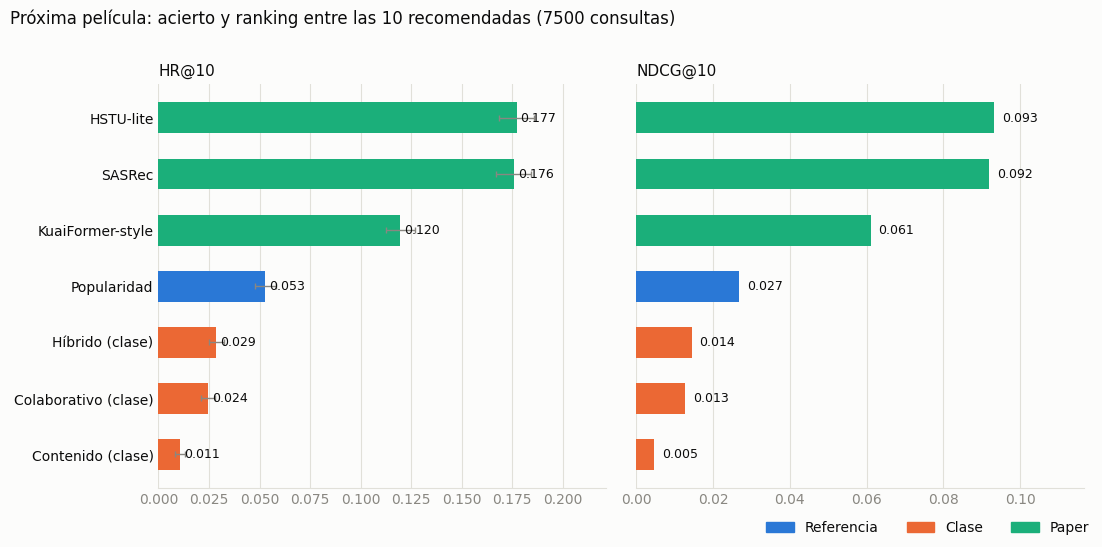

In [13]:
import matplotlib.pyplot as plt

COL = {"Referencia": "#2a78d6", "Clase": "#eb6834", "Paper": "#1baf7a"}     # un color fijo por grupo
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"

t = tabla().sort_values(f"NDCG@{K}")
fig, axes = plt.subplots(1, 2, figsize=(11, 0.55 * len(t) + 1.6), sharey=True, facecolor=SURFACE)
for ax, col, err in zip(axes, [f"HR@{K}", f"NDCG@{K}"], [t["± IC95"].to_numpy(), None]):
    ax.set_facecolor(SURFACE)
    ax.barh(t.index, t[col], height=0.55, color=[COL[g] for g in t["Grupo"]], xerr=err,
            error_kw=dict(ecolor=MUTED, lw=1, capsize=2))
    for y, v in enumerate(t[col]):
        ax.text(v + 0.002, y, f"{v:.3f}", va="center", ha="left", fontsize=9, color=INK)
    ax.set_title(col, loc="left", fontsize=11, color=INK)
    ax.set_xlim(0, t[col].max() * 1.25)
    ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID); ax.tick_params(colors=MUTED, length=0)
axes[0].tick_params(axis="y", colors=INK, labelsize=10)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()]
fig.legend(handles, COL.keys(), loc="lower right", ncol=3, frameon=False, labelcolor=INK)
fig.suptitle(f"Próxima película: acierto y ranking entre las {K} recomendadas ({Q} consultas)", x=0.01, ha="left", color=INK)
plt.tight_layout(rect=(0, 0.04, 1, 0.97)); plt.show()

### Matriz de confusión

Filas: lo que realmente pasó. Columnas: lo que recomendó el método. La mayoría del catálogo cae en TN (ni recomendada ni vista), por eso importan más TP, FP y FN.

In [14]:
def conf_df(c):
    return pd.DataFrame([[c["TP"], c["FN"]], [c["FP"], c["TN"]]],
                        index=["Vista después", "No vista después"], columns=["Recomendada", "No recomendada"])

for key, titulo in [("conf", "Evaluación iterativa (próxima película, todos los pasos)"),
                    ("conf_w", f"Ventana futura (recomendar una vez y mirar las {N_ROLL} siguientes)")]:
    print(titulo)
    display(pd.DataFrame({n: r[key] for n, r in RESULTS.items()}).T[["TP", "FP", "FN", "TN"]])

mejor = tabla().index[0]
print(f"\nMatriz del mejor método por NDCG@{K}: {mejor} (evaluación iterativa)")
display(conf_df(RESULTS[mejor]["conf"]))

Evaluación iterativa (próxima película, todos los pasos)


,TP,FP,FN,TN
Popularidad,397,74603,7103,20797197
Contenido (clase),80,74920,7420,20796880
Colaborativo (clase),183,71473,7317,20800327
Híbrido (clase),215,71441,7285,20800359
SASRec,1319,73681,6181,20798119
HSTU-lite,1329,73671,6171,20798129
KuaiFormer-style,898,74102,6602,20797698


Ventana futura (recomendar una vez y mirar las 5 siguientes)


,TP,FP,FN,TN
Popularidad,386,14614,7114,4156746
Contenido (clase),80,14920,7420,4156440
Colaborativo (clase),170,13979,7330,4157381
Híbrido (clase),194,13955,7306,4157405
SASRec,1031,13969,6469,4157391
HSTU-lite,1029,13971,6471,4157389
KuaiFormer-style,727,14273,6773,4157087



Matriz del mejor método por NDCG@10: HSTU-lite (evaluación iterativa)


,Recomendada,No recomendada
Vista después,1329,6171
No vista después,73671,20798129


### Un caso concreto

Para mirar si las recomendaciones tienen sentido: las últimas películas del historial de un usuario, las recomendaciones de cada método en el paso 0 y lo que el usuario vio después.

In [15]:
def ejemplo(u=0, n_hist=5, n_show=5):
    titles = movies["title"].to_numpy()
    q = u * N_ROLL
    print(f"Usuario #{u}. Últimas {n_hist} películas del historial de entrenamiento:")
    for i in seq_items[u][n_train[u] - n_hist:n_train[u]]:
        print("   ", titles[i])
    print(f"\nLo que vio después ({N_ROLL}):")
    for i in seq_items[u][n_train[u]:]:
        print("   ", titles[i])
    for nombre, r in RESULTS.items():
        print(f"\n{nombre}:")
        for i in r["recs"][q][:n_show]:
            if i >= 0:
                print("   ", titles[i], "  <- acierto" if i in set(seq_items[u][n_train[u]:]) else "")

ejemplo(0)

Usuario #0. Últimas 5 películas del historial de entrenamiento:
    Star Wars: Episode IV - A New Hope (1977)
    Mighty Aphrodite (1995)
    Nutty Professor, The (1996)
    Striptease (1996)
    Down Periscope (1996)

Lo que vio después (5):
    Phenomenon (1996)
    Primal Fear (1996)
    Multiplicity (1996)
    Up Close and Personal (1996)
    Spy Hard (1996)

Popularidad:
    Pulp Fiction (1994) 
    Forrest Gump (1994) 
    Silence of the Lambs, The (1991) 
    Shawshank Redemption, The (1994) 
    Jurassic Park (1993) 

Contenido (clase):
    Moonrise Kingdom (2012) 
    American President, The (1995) 
    Postman, The (Postino, Il) (1994) 
    Waiting to Exhale (1995) 
    (500) Days of Summer (2009) 

Colaborativo (clase):
    Godfather, The (1972) 
    Shawshank Redemption, The (1994) 
    Casablanca (1942) 
    Goodfellas (1990) 
    L.A. Confidential (1997) 

Híbrido (clase):
    American Beauty (1999) 
    Casablanca (1942) 
    Election (1999) 
    Great Dictator, The (194

In [16]:
t = tabla()
mejor, mejor_clase = t.index[0], t[t["Grupo"] == "Clase"].index[0]
print(f"Mejor método por NDCG@{K}: {mejor} ({t.loc[mejor, f'NDCG@{K}']:.4f}), HR@{K} = {t.loc[mejor, f'HR@{K}']:.4f} ± {t.loc[mejor, '± IC95']:.4f}")
print(f"Mejor método de la clase: {mejor_clase} ({t.loc[mejor_clase, f'NDCG@{K}']:.4f})")
paper = t[t["Grupo"] == "Paper"]
if len(paper):
    mejor_paper = paper.index[0]
    d = t.loc[mejor_paper, f"HR@{K}"] - t.loc[mejor_clase, f"HR@{K}"]
    ic = t.loc[mejor_paper, "± IC95"] + t.loc[mejor_clase, "± IC95"]
    print(f"Mejor método del paper: {mejor_paper}. Diferencia de HR@{K} contra {mejor_clase}: {d:+.4f} "
          f"({'dentro del margen de error, no concluyente' if abs(d) < ic else 'fuera del margen de error'})")
pop_hr = t.loc["Popularidad", f"HR@{K}"]
print(f"Popularidad (referencia): HR@{K} = {pop_hr:.4f}. Un método que no la supera no está aportando personalización.")

Mejor método por NDCG@10: HSTU-lite (0.0933), HR@10 = 0.1772 ± 0.0086
Mejor método de la clase: Híbrido (clase) (0.0144)
Mejor método del paper: HSTU-lite. Diferencia de HR@10 contra Híbrido (clase): +0.1485 (fuera del margen de error)
Popularidad (referencia): HR@10 = 0.0529. Un método que no la supera no está aportando personalización.


## Cómo leer los resultados y qué falta

- Los intervalos de confianza dependen de la cantidad de usuarios de la muestra, y los hiperparámetros no están ajustados (solo se corta por early stopping). La tabla de semillas muestra cuánto varía cada modelo neuronal; las diferencias menores a ese desvío no son concluyentes. Cambiar `SEED`, `N_USERS` o `N_ROLL` puede mover el orden entre métodos cercanos.
- El paper insiste en que las ventajas de los modelos generativos aparecen con **escala** (más datos, más usuarios, modelos más grandes, sección 5.1) y con **contenido rico** (texto e imágenes procesados por LLMs, secciones 3.1 y 4.3). Esta muestra de MovieLens no tiene ninguna de las dos cosas, así que esta comparación no prueba ni refuta lo que dice el paper.
- Extensiones naturales: reemplazar el contenido por embeddings de títulos con un codificador de texto preentrenado (por ejemplo `sentence-transformers`), probar `ml-1m` para tener más escala, y evaluar el cold start escondiendo todas las películas de un conjunto de ítems.